In [133]:
#General imports and preprocessing
import os
import numpy as np
import pandas as pd
import re
from tqdm.notebook import tqdm
tqdm.pandas()

#Feature Extraction
from sklearn.feature_extraction.text import CountVectorizer 
from sklearn.feature_extraction.text import TfidfVectorizer

#Feature engineering
from nltk import tokenize
from textblob import TextBlob
from nltk.corpus import stopwords
from nltk import pos_tag
import gensim.models.keyedvectors as word2vec
from nltk.corpus import wordnet as wn
from nltk.corpus import sentiwordnet as swn
from nltk.stem import WordNetLemmatizer
from scipy.spatial.distance import cosine

#Visualization
from wordcloud import WordCloud
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

#Transformations
from sklearn.preprocessing import minmax_scale

#Modeling
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn import svm
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
import pickle, joblib


/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/tqdm/std.py:651: FutureWarning: The Panel class is removed from pandas. Accessing it from the top-level namespace will also be removed in the next version
  from pandas import Panel


## Preprocessing and Basic Feature Engineering

In [13]:
def get_basic_features(df):
    '''Creates basic features for the given text'''
    text = str(df['content'])
    text_split = text.split()
    upper_count = 0
    upper_words = list()
    word_count = 0
    numeric_count = 0
    each_word_len = list()
    text_length = len(text)
    #sometimes punctuations might include space
    punct_count = len(re.sub('\w+','',text).split())
    unique_word_count = len(pd.value_counts(text_split).index)
    for word in text_split:
        word_count += 1
        each_word_len.append(len(word))
        if word.isupper() and len(word)>1:
            upper_count += 1
            upper_words.append(word)
        elif word.isnumeric():
            numeric_count += 1
    return upper_count, upper_words, word_count, np.mean(each_word_len), text_length, punct_count, numeric_count, unique_word_count


englishStopWords = stopwords.words('english')
def stop_words_percent(text):
    '''find the percentage of stop words in each article'''
    try:
        words_in_text = text.split()
        return len([word for word in words_in_text if word in englishStopWords])/len(words_in_text)
    except:
        return 0


#list of all common columns for concatination
column_list = ['content','actual_heading','clean_content','upper_words','upper_count','word_count',
               'mean(each_word_len)','unique_word_count','punct_count','numeric_count','text_length',
               'stop_words_percent','is_positive']


## The Better India articles

In [18]:
#First time procssing raw articles
def clean_articles(text):
    '''cleans one article at a time - removes punctuation, leading and trailing unwanted text if any, standardize case
    and returns the tokenized text
    all the characters encoded are quotation marks, hifen or someother form of punctuation, either way we will be 
    removing them so its better to directly replace all the non-word charcters before decoding them to keep the number 
    of steps to a minimum'''

    temp = re.sub("\W+",' ',text)
    temp = re.sub(" s |by.*?[am|pm] |Get the best positive stories straight into your inbox",' ',temp).lower().strip()
    try:
        temp = re.sub(r"\n",'',text)
        temp = re.sub(r"\[.*\]",'',temp)
    except:
        temp = text
        pass

    return temp

tbi_data['clean_content'] = tbi_data['content'].apply(clean_articles)
tbi_data[['upper_count', 'upper_words', 'word_count', 'mean(each_word_len)', 'text_length', 'punct_count', 'numeric_count', 'unique_word_count']] = tbi_data.apply(get_basic_features, axis=1, result_type='expand')
tbi_data['stop_words_percent'] = tbi_data['content'].apply(lambda val: stop_words_percent(val))
tbi_data['is_positive'] = 1

In [23]:
#preprocessed and stored articles
tbi_data = pd.read_csv("/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/tbi_data.csv")
tbi_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6620 entries, 0 to 6619
Data columns (total 13 columns):
content                6620 non-null object
actual_heading         6620 non-null object
clean_content          6620 non-null object
upper_words            6620 non-null object
upper_count            6620 non-null int64
word_count             6620 non-null int64
mean(each_word_len)    6620 non-null float64
unique_word_count      6620 non-null int64
punct_count            6620 non-null int64
numeric_count          6620 non-null int64
text_length            6620 non-null int64
stop_words_percent     6620 non-null float64
is_positive            6620 non-null int64
dtypes: float64(2), int64(7), object(4)
memory usage: 672.5+ KB


### Indian Express Articles

In [21]:
#first time processing

ie_path = '/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/IndianExpress/'
ie_files_list = os.listdir(ie_path)
ie_data = pd.DataFrame()
for file in ie_files_list[:15]:
    ie_data = pd.concat([ie_data,pd.read_csv(ie_path+file,encoding='unicode-escape')])
    
ie_data.drop(labels=['Unnamed: 0'],inplace=True,axis=1)
ie_data.reset_index(drop=True,inplace=True)
ie_data.head()

ie_data['Heading'] = ie_data['Heading'].apply(lambda heading: re.sub(' - Indian Express $| - Indian Express$|\W+',' ',heading).strip())
ie_data['Content'] = ie_data['Content'].apply(lambda content: re.sub(r'\r\n|\r<p>','',content).strip())
ie_data['Clean_content'] = ie_data['Content'].apply(lambda content: re.sub('[^ \w+]','',content.replace('.','. ').lower()))

ie_data.rename(columns={'Heading':'actual_heading','Content':'content','Clean_content':'clean_content'},inplace=True)

ie_data[['upper_count', 'upper_words', 'word_count', 'mean(each_word_len)', 'text_length', 'punct_count', 'numeric_count', 'unique_word_count']] = ie_data.apply(get_basic_features,axis=1,result_type='expand')
ie_data['stop_words_percent'] = ie_data['content'].apply(lambda val: stop_words_percent(val))
ie_data['is_positive'] = 0

ie_data = ie_data[column_list]


In [22]:
#preprocessed and stored articles 15k
ie_path = '/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/IndianExpress/'
ie_data = pd.read_csv(ie_path+'ie_data_15k.csv')
ie_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15015 entries, 0 to 15014
Data columns (total 13 columns):
content                15015 non-null object
actual_heading         15015 non-null object
clean_content          15015 non-null object
upper_words            15015 non-null object
upper_count            15015 non-null int64
word_count             15015 non-null int64
mean(each_word_len)    15015 non-null float64
unique_word_count      15015 non-null int64
punct_count            15015 non-null int64
numeric_count          15015 non-null int64
text_length            15015 non-null int64
stop_words_percent     15015 non-null float64
is_positive            15015 non-null int64
dtypes: float64(2), int64(7), object(4)
memory usage: 1.5+ MB


## TOI articles

In [14]:
#toi_data = pd.read_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TOI/toi_10k.csv')
#toi_data.dropna(inplace=True)

def clean_toi(text):    
    '''cleans the text by removing new line, trailing and leading single quote, encoded characters. We do not have any html tags to clean'''
    try:
        temp = re.sub(r"\\n"," ",text)
        temp = re.sub(r"\\x[a-z][0-9]*|\\x[0-9]*","'",temp)
        temp = re.sub(r"'''","'",temp)
        temp = re.sub(r"^b'|^b\"","",temp)
        temp = re.sub(r"'$","",temp).strip().lower()

        return temp
    except:
        return None

toi_data.rename(columns={'heading':'actual_heading'},inplace=True)
toi_data['clean_content'] = toi_data['content'].apply(clean_toi)
toi_data[['upper_count', 'upper_words', 'word_count', 'mean(each_word_len)', 'text_length', 'punct_count', 'numeric_count', 'unique_word_count']] = toi_data.apply(get_basic_features,axis=1,result_type='expand')
toi_data['stop_words_percent'] = toi_data['content'].apply(lambda val: stop_words_percent(val))
toi_data['is_positive'] = 0

In [21]:
#read the preprocessed articles around 13k from csv
toi_data = pd.read_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/TOI/toi_data_13k.csv')
toi_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12718 entries, 0 to 12717
Data columns (total 13 columns):
actual_heading         12718 non-null object
content                12718 non-null object
clean_content          12718 non-null object
upper_count            12718 non-null int64
upper_words            12718 non-null object
word_count             12718 non-null int64
mean(each_word_len)    12718 non-null float64
text_length            12718 non-null int64
punct_count            12718 non-null int64
numeric_count          12718 non-null int64
unique_word_count      12718 non-null int64
stop_words_percent     12718 non-null float64
is_positive            12718 non-null int64
dtypes: float64(2), int64(7), object(4)
memory usage: 1.3+ MB


## All data

In [109]:
#concat both the dataframes
#this will not be used directly since the combined preprocessed data is stored as all_data_org.csv and it can be loaded directly
#all_data = pd.concat([tbi_data[column_list],ie_data[column_list],toi_data[column_list]],ignore_index=True)

contractions = { 
"ain't": "am not / are not / is not / has not / have not",
"aren't": "are not / am not",
"can't": "cannot",
"can't've": "cannot have",
"'cause": "because",
"could've": "could have",
"couldn't": "could not",
"couldn't've": "could not have",
"didn't": "did not",
"doesn't": "does not",
"don't": "do not",
"hadn't": "had not",
"hadn't've": "had not have",
"hasn't": "has not",
"haven't": "have not",
"he'd": "he had / he would",
"he'd've": "he would have",
"he'll": "he shall / he will",
"he'll've": "he shall have / he will have",
"he's": "he has / he is",
"how'd": "how did",
"how'd'y": "how do you",
"how'll": "how will",
"how's": "how has / how is / how does",
"I'd": "I had / I would",
"I'd've": "I would have",
"I'll": "I shall / I will",
"I'll've": "I shall have / I will have",
"I'm": "I am",
"I've": "I have",
"isn't": "is not",
"it'd": "it had / it would",
"it'd've": "it would have",
"it'll": "it shall / it will",
"it'll've": "it shall have / it will have",
"it's": "it has / it is",
"let's": "let us",
"ma'am": "madam",
"mayn't": "may not",
"might've": "might have",
"mightn't": "might not",
"mightn't've": "might not have",
"must've": "must have",
"mustn't": "must not",
"mustn't've": "must not have",
"needn't": "need not",
"needn't've": "need not have",
"o'clock": "of the clock",
"oughtn't": "ought not",
"oughtn't've": "ought not have",
"shan't": "shall not",
"sha'n't": "shall not",
"shan't've": "shall not have",
"she'd": "she had / she would",
"she'd've": "she would have",
"she'll": "she shall / she will",
"she'll've": "she shall have / she will have",
"she's": "she has / she is",
"should've": "should have",
"shouldn't": "should not",
"shouldn't've": "should not have",
"so've": "so have",
"so's": "so as / so is",
"that'd": "that would / that had",
"that'd've": "that would have",
"that's": "that has / that is",
"there'd": "there had / there would",
"there'd've": "there would have",
"there's": "there has / there is",
"they'd": "they had / they would",
"they'd've": "they would have",
"they'll": "they shall / they will",
"they'll've": "they shall have / they will have",
"they're": "they are",
"they've": "they have",
"to've": "to have",
"wasn't": "was not",
"we'd": "we had / we would",
"we'd've": "we would have",
"we'll": "we will",
"we'll've": "we will have",
"we're": "we are",
"we've": "we have",
"weren't": "were not",
"what'll": "what shall / what will",
"what'll've": "what shall have / what will have",
"what're": "what are",
"what's": "what has / what is",
"what've": "what have",
"when's": "when has / when is",
"when've": "when have",
"where'd": "where did",
"where's": "where has / where is",
"where've": "where have",
"who'll": "who shall / who will",
"who'll've": "who shall have / who will have",
"who's": "who has / who is",
"who've": "who have",
"why's": "why has / why is",
"why've": "why have",
"will've": "will have",
"won't": "will not",
"won't've": "will not have",
"would've": "would have",
"wouldn't": "would not",
"wouldn't've": "would not have",
"y'all": "you all",
"y'all'd": "you all would",
"y'all'd've": "you all would have",
"y'all're": "you all are",
"y'all've": "you all have",
"you'd": "you had / you would",
"you'd've": "you would have",
"you'll": "you shall / you will",
"you'll've": "you shall have / you will have",
"you're": "you are",
"you've": "you have"
}


def rem_contractions(text):
    text = str(text)
    rep = dict((re.escape(k), v) for k, v in contractions.items()) 
    pattern = re.compile("|".join(rep.keys()))
    text = pattern.sub(lambda m: rep[re.escape(m.group(0))], text)
    return text


def lemmatize_with_postag(sentence):
    sentence = str(sentence)
    sent = TextBlob(sentence)
    tag_dict = {"J": 'a', 
                "N": 'n', 
                "V": 'v', 
                "R": 'r'}
    words_and_tags = [(w, tag_dict.get(pos[0], 'n')) for w, pos in sent.tags]    
    lemmatized_list = [wd.lemmatize(tag) for wd, tag in words_and_tags if wd not in englishStopWords]
    return " ".join(lemmatized_list)



def pos_sentence(text):
    '''converts a text with words to text with pos tags for the respective words'''
    text = str(text)
    words_and_tags = pos_tag(text.split())
    pos_sent = list()
    for word, tag in words_and_tags:
        pos_sent.append(tag)
        
    return ' '.join(pos_sent)



#from operator import itemgetter
def most_used_adjectives(row,top=5):
    text = str(row['lemmatized_content'])
    adj_list = list()
    #currently -3 index is lemmatized text
    sent_split = text.split()
    for word,tag in pos_tag(sent_split):
        if tag.lower() in ['jj','jjr','jjs']:
            adj_list.append(word)

    
    return list(pd.value_counts(adj_list).index[:top]),len(adj_list)



wv = word2vec.KeyedVectors.load_word2vec_format("/Users/gurumanikanta/Documents/DS-Analytics/GoogleNews-vectors-negative300.bin.gz",binary=True)

###most used adjectives similarity with words "good" and "bad" to determine the goodness of articles
def pos_neg_score(row):
    '''returns the average positive/negative scores based on top adjectives'''
    pos_score = 0
    neg_score = 0
    adjectives = row['most_used_adjectives']
    num_adj = len(adjectives)
    for adj in adjectives:
        try:
            pos_score = pos_score + wv.similarity(adj,'good')
        except:
            pass
        try:
            neg_score = neg_score + wv.similarity(adj,'neg')
        except:
            pass
    
    if num_adj == 0:
        avg_pos, avg_neg = 0, 0
    else:
        avg_pos, avg_neg = pos_score/num_adj, neg_score/num_adj
        
    return avg_pos, avg_neg




def doc_similarity_to_pos(sim_demo):
    '''calculates the similarity of all articles to the positive articles'''
    cos_sim = dict()
    vocab = wv.vocab
    for i in range(6628):
        pos_article = sim_demo['lemmatized_content'][i]
        if not pd.isnull(pos_article):
            pos_vec = np.mean([wv[word] for word in pos_article.split() if (word in vocab)],axis=0)
            cos_sim['article_'+str(i)] = list()
            for d in range(len(sim_demo)):
                demo_article = sim_demo['lemmatized_content'][d]
                if not pd.isnull(demo_article):
                    demo_vec = np.mean([wv[word] for word in demo_article.split() if (word in vocab)],axis=0)
                    cos_sim['article_'+str(i)].append(cosine(pos_vec,demo_vec))
                else:
                    cos_sim['article_'+str(i)].append(None)
        else:
            continue

    for key in cos_sim.keys():
        cos_sim[key] = np.mean(cos_sim['key'])

    sim_df = pd.DataFrame(data=cos_sim)
    return sim_df.apply(np.mean,axis=1)




####sentiments
def penn_to_wn(tag):
    #Convert between the PennTreebank tags to simple Wordnet tags
    if tag.startswith('J'):
        return wn.ADJ
    elif tag.startswith('N'):
        return wn.NOUN
    elif tag.startswith('R'):
        return wn.ADV
    elif tag.startswith('V'):
        return wn.VERB
    return None

lemmatizer = WordNetLemmatizer()
def get_document_sentiment(text):
    text = str(text)
    score = 0.0
    tokens_count = 0
 
    tagged_text = pos_tag(tokenize.word_tokenize(str(text)))

    for word, tag in tagged_text:
        wn_tag = penn_to_wn(tag)
        if wn_tag not in (wn.NOUN, wn.ADJ, wn.ADV):
            continue

        lemma = lemmatizer.lemmatize(word, pos=wn_tag)
        if not lemma:
            continue

        synsets = wn.synsets(lemma, pos=wn_tag)
        if not synsets:
            continue

        # The most commonly used form of the word
        synset = synsets[0]
        swn_synset = swn.senti_synset(synset.name())

        score += swn_synset.pos_score() - swn_synset.neg_score()
        tokens_count += 1

    if not tokens_count:
        return 0
 
    return score/tokens_count


def mean_adjective_length(row):
    '''iterates one row at a time, identifies all adjectives and returns mean length of all adjectives'''
    text = str(row['lemmatized_content'])
    adj_list = list()
    adj_len_list = list()
    
    try:                
        sent_split = text.split()
        for word,tag in pos_tag(sent_split):
            if tag.lower() in ['jj','jjr','jjs']:
                adj_list.append(word)
                adj_len_list.append(len(word))
                

        return np.mean(np.array(adj_len_list)),' '.join(adj_list)
    except:
        return 0


def norm_numerical_features(all_data_temp):
    '''Creates a normalized feature for all the numerical features available'''
    all_data_temp['norm_adj_count'] = all_data_temp['adj_count']/all_data_temp['word_count']
    all_data_temp['norm_upper_count'] = all_data_temp['upper_count']/all_data_temp['word_count']
    all_data_temp['norm_numeric_count'] = all_data_temp['numeric_count']/all_data_temp['word_count']
    all_data_temp['norm_unique_word_count'] = all_data_temp['unique_word_count']/all_data_temp['word_count']
    all_data_temp['norm_punct_count'] = all_data_temp['punct_count']/all_data_temp['text_length']

    return all_data_temp

In [28]:
all_data = norm_numerical_features(all_data)
all_data['content_sentiment'] = all_data['clean_content'].apply(get_document_sentiment)
all_data['clean_content'] = all_data['clean_content'].apply(rem_contractions)
all_data['lemmatized_content'][6620:21635] = all_data['clean_content'].apply(lemmatize_with_postag)
all_data['pos_content'] = all_data['lemmatized_content'].apply(pos_sentence)
all_data[['most_used_adjectives','adj_count']] = all_data.apply(most_used_adjectives,axis=1,result_type='expand')
all_data[['positive_score','negative_score']] = all_data.apply(pos_neg_score,axis=1,result_type='expand')
#all_data['similarity_to_pos'] = doc_similarity_to_pos(all_data)
all_data[['mean_adj_length','all_adjs']] = all_data.apply(mean_adjective_length,axis=1,result_type='expand')
all_data['mean_adj_length'].fillna(0,inplace=True)
all_data['norm_adj_count'] = all_data['adj_count'] / all_data['word_count']

all_data['heading_sentiment'] = all_data['actual_heading'].apply(get_document_sentiment)
all_data['lemmatized_heading'] = all_data['actual_heading'].apply(lemmatize_with_postag)
all_data['pos_heading'] = all_data['lemmatized_heading'].apply(pos_sentence)


/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/numpy/core/fromnumeric.py:3118: RuntimeWarning: Mean of empty slice.
  out=out, **kwargs)


In [164]:
#use this to get all data after applying all preprocessing functions without tfidf, countvec, word2vec
all_data_org = pd.read_csv('/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/all_data_original.csv')

In [80]:
#change all_data to all_data_org
x = np.array(all_data_org.drop(labels=['is_positive'],axis=1))
y = np.array(all_data_org['is_positive'])

sss = StratifiedShuffleSplit(n_splits=1,random_state=16)
for train_ind, test_ind in sss.split(X = np.zeros(len(x)), y = y):
    all_data, all_data_test = x[train_ind], x[test_ind]
    y_train, y_test = y[train_ind], y[test_ind]

all_data = all_data.loc[train_ind,:]

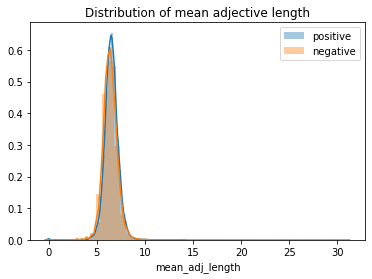

In [62]:
plt.title('Distribution of mean adjective length')
sns.distplot(all_data[all_data['is_positive']==1]['mean_adj_length'],label='positive')
sns.distplot(all_data[all_data['is_positive']==0]['mean_adj_length'],label='negative')
plt.legend()

In [17]:
adv_forms = ['rb','rbr','rbs']
adj_forms = ['jj','jjr','jjs']
noun_forms = ['nn','nns','nnp','nnps']
verb_forms = ['vb','vbd','vbg','vbn','vbp','vbz']

adverbs_only = pd.Series()
adj_only = pd.Series()
noun_only = pd.Series()
verb_only = pd.Series()

forms_list = [adv_forms,adj_forms,noun_forms,verb_forms]
pos_list = [adverbs_only,adj_only,noun_only,verb_only]

def words_of_tag(tag_word_pair):
    '''change the pos_form list as required to return one of the 4 above forms'''
    if tag_word_pair[1].lower() in forms:
        return tag_word_pair[0]

def word_tagging(text):
    req_words = list()
    try:
        word_and_tag = pos_tag(text.split())
        req_words.append(pd.Series(word_and_tag).apply(words_of_tag))
        return ' '.join(req_words[0].dropna().values)
    except:
        return None

    
for pos,forms in zip(pos_list,forms_list):
    pos = pos.append(all_data['lemmatized_content'].progress_apply(word_tagging))
    

In [15]:
nava = pd.concat([noun_only,adj_only,verb_only,adverbs_only],axis=1)
nava.columns = ['noun','adjective','verb','adverb']
nava['is_positive'] = all_data['is_positive']
nava.head()

,noun,adjective,verb,adverb,is_positive
0,be arrive be be die be tell have go felt have ...,be arrive be be die be tell have go felt have ...,be arrive be be die be tell have go felt have ...,be arrive be be die be tell have go felt have ...,1
1,give have replace be grow be combine create be...,give have replace be grow be combine create be...,give have replace be grow be combine create be...,give have replace be grow be combine create be...,1
2,find leave be teach stop come have do have com...,find leave be teach stop come have do have com...,find leave be teach stop come have do have com...,find leave be teach stop come have do have com...,1
3,have be be have be be examine be be be give re...,have be be have be be examine be be be give re...,have be be have be be examine be be be give re...,have be be have be be examine be be be give re...,1
4,be prove be take address s be work have have b...,be prove be take address s be work have have b...,be prove be take address s be work have have b...,be prove be take address s be work have have b...,1


In [16]:
nava['adjective'][0]

'be arrive be be die be tell have go felt have be do save be have leave meet let lose end do understand change have tell ask have finish i be say be light take earn s have couldn let go fee grow help ease be develop be be encompass shape s pass make realise assess do doctor be behave do be ask be i talk advise set have come come be draw continue do i believe have work have work have want lead have red take be persuade get have reckon be be enjoy trust be be fell think make marry be set pioneer be accompany pick listen grasp find be play announce want catch ponder have be be go hold face start hear be marry have child wonder be question do be talk protect work become have teach have introduce soni be do report use think be lie sit seek understand view discover be alien believe be be accept be push be understand do know believe be believe be believe be be form get embed kill be travel touch hence be explain'

## Exploratory Data Analysis and Viz

(-0.5, 1199.5, 899.5, -0.5)

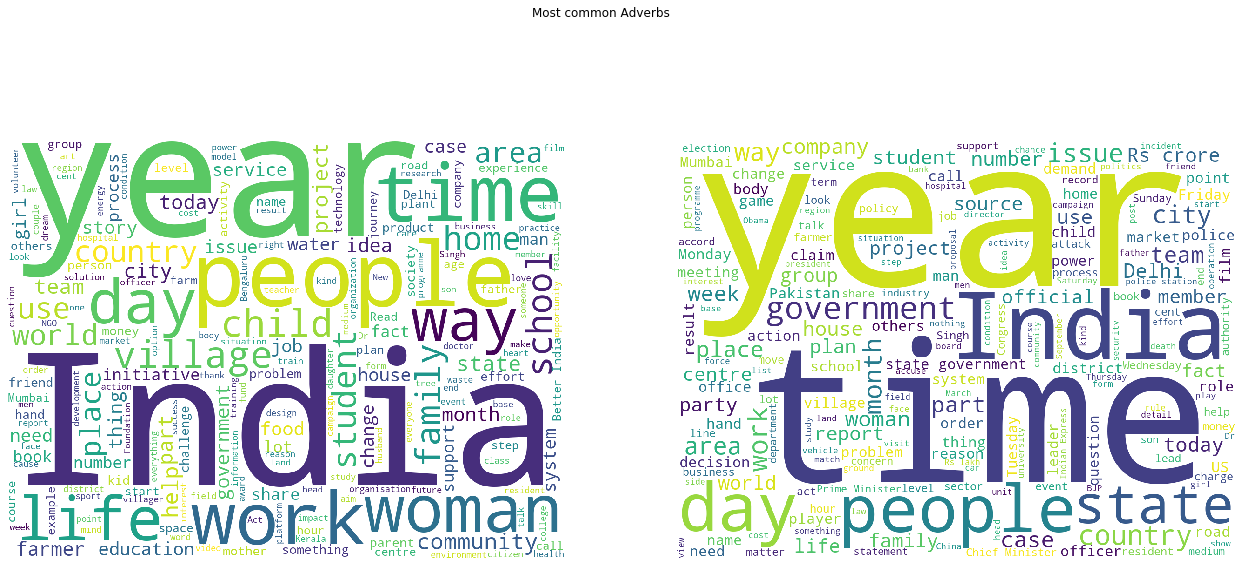

In [702]:
wc = WordCloud(width=1200,height=900,background_color='white',min_font_size=10,stopwords=englishStopWords)

fig, ax = plt.subplots(1,2,figsize = (22,10))
fig.suptitle('Most common Adverbs')

ax[0].imshow(wc.generate(' '.join(nava[nava['is_positive']==1]['noun'].values)))
ax[0].axis('off')
ax[1].imshow(wc.generate(' '.join(nava[nava['is_positive']==0]['noun'].values)))
ax[1].axis('off')

In [458]:
for head in all_data['actual_heading'][7020:7030]:
    print(head)

Grandson denied ticket Jaffer resigns
RS Left MPs walk out over cut in Kerala food quota
Cong clips wings of some gen secys
Cabinet may clear bid to give benefits to SC motherâ s child
Maya dissolves BSP district units orders â sarvajanâ makeover
Arjun under fire Army wants another MBT
IITs plan to set up virtual universities labs
US releases Syria reactor images
US Govt dos donâ ts on terror lingo
Who does he think he is GOP ads target Obama


In [461]:
print(pos_sentence('Kerala Writes History With India’s First Transgender Policy'))
print(pos_sentence('Cabinet may clear bid to give benefits to SC motherâ s child'))

NNP VBZ NNP IN NNP NNP NNP NN
NNP MD VB NN TO VB NNS TO NNP NN NN NN


In [63]:
print(max(all_data[all_data['is_positive']==1]['heading_sentiment']),min(all_data[all_data['is_positive']==1]['heading_sentiment']))
print(max(all_data[all_data['is_positive']==0]['heading_sentiment']),min(all_data[all_data['is_positive']==0]['heading_sentiment']))

0.875 -0.75
0.875 -0.875


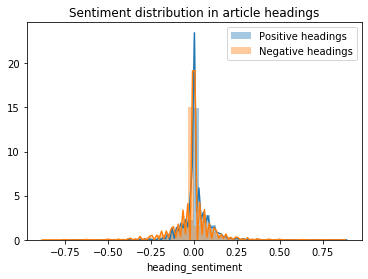

In [64]:
plt.title('Sentiment distribution in article headings')
sns.distplot(all_data[all_data['is_positive']==1]['heading_sentiment'],label='Positive headings')
sns.distplot(all_data[all_data['is_positive']==0]['heading_sentiment'],label='Negative headings')
plt.legend()

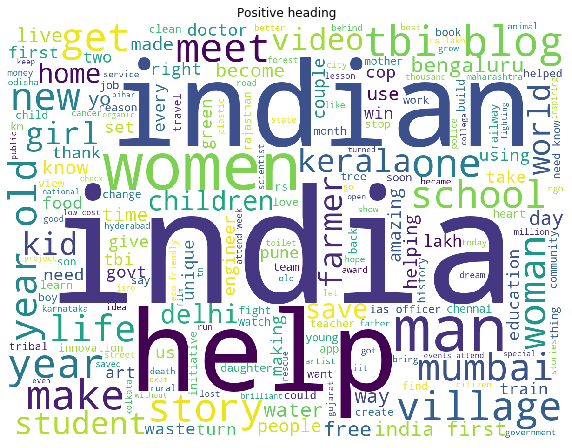

In [97]:
wc = WordCloud(width=1200,height=900,background_color='white',min_font_size=10,stopwords=englishStopWords)
plt.figure(figsize=(10,14))
plt.axis('off')
plt.title('Positive heading')
plt.imshow(wc.generate(' '.join(all_data[all_data['is_positive']==1]['lemmatized_heading'].values)))
#most articles are about help, change, women, cleanliness, inspiration and ingenious & indigenous

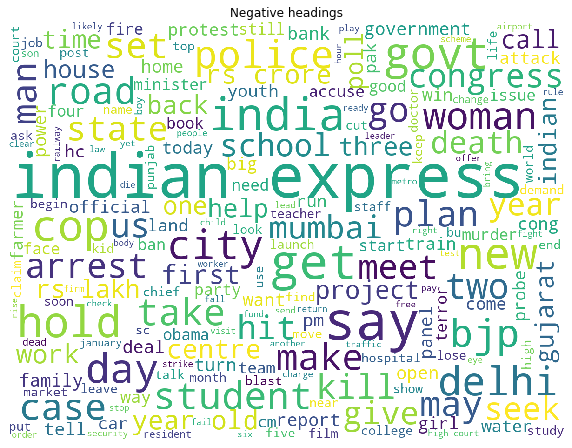

In [98]:
plt.figure(figsize=(10,14))
plt.axis('off')
plt.title('Negative headings')
plt.imshow(wc.generate(' '.join(all_data[all_data['is_positive']==0]['lemmatized_heading'].values)))
#looks like most articles are about politics, accidents, law, death/crime and terrorism

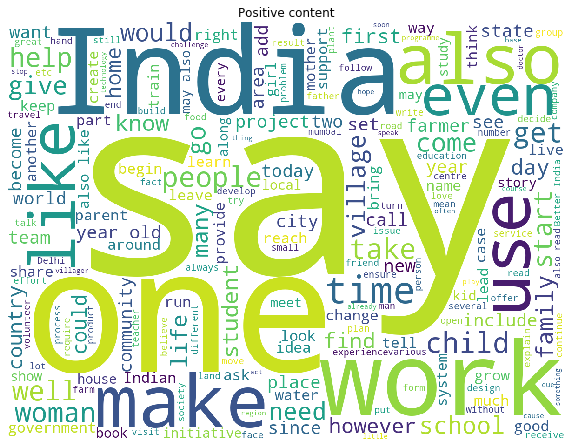

In [99]:
plt.figure(figsize=(10,14))
plt.axis('off')
plt.title('Positive content')
plt.imshow(wc.generate(' '.join(all_data[all_data['is_positive']==1]['lemmatized_content'].values)))

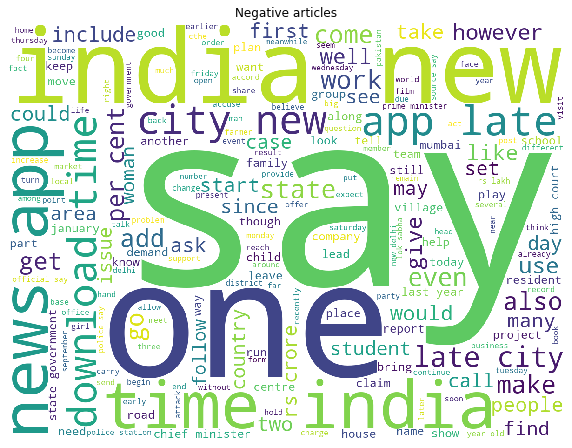

In [100]:
plt.figure(figsize=(10,14))
plt.axis('off')
plt.title('Negative articles')
plt.imshow(wc.generate(' '.join(all_data[all_data['is_positive']==0]['lemmatized_content'].values)))

In [74]:
pn = [0,1]
#top 30 words before removing stopwords - positve and negative articles
for state in pn:
    word_list = ' '.join(all_data[all_data['is_positive']==state]['clean_content'].values).split()
    top_30_words_stop = pd.value_counts(word_list)
    print('{}:\n{}'.format(state,top_30_words_stop[:31]))

##not at all helpful, since most of those are common words for every day speech - the,a,that,an,with...

0:
the     555652
of      239522
to      227050
and     201389
in      179060
a       168670
for      92702
on       85333
is       80081
that     77511
was      64537
said     56028
with     52957
has      47707
from     47346
at       46370
be       46142
by       45584
as       45249
have     44288
The      42617
it       40988
he       39550
are      39548
will     37025
not      36562
had      35400
his      31477
an       29103
were     27289
been     26838
dtype: int64
1:
the      201601
to       118957
and      111990
of       110056
a         87632
in        78571
is        44047
for       38931
that      36734
with      28266
was       27336
on        23978
The       23968
are       21839
from      21509
as        19749
by        19416
their     18156
I         18075
have      17329
has       17303
it        17021
at        16450
be        15826
this      15729
an        15591
his       14793
he        14113
her       13635
also      13191
not       12635
dtype: int64


In [87]:
all_data.loc[12022,:]

content                 The crime Branch has arrested two men for runn...
actual_heading          Guard faces 10 years in jail for selling govt ...
clean_content           The crime Branch has arrested two men for runn...
upper_words             ['NGO', 'NGO,', 'NGO,', 'NGO', 'CNG', 'DCP', '...
upper_count                                                             7
word_count                                                            259
mean(each_word_len)                                               4.89189
unique_word_count                                                     161
punct_count                                                            27
numeric_count                                                           2
text_length                                                          1525
stop_words_percent                                               0.355212
is_positive                                                             0
content_sentiment                     

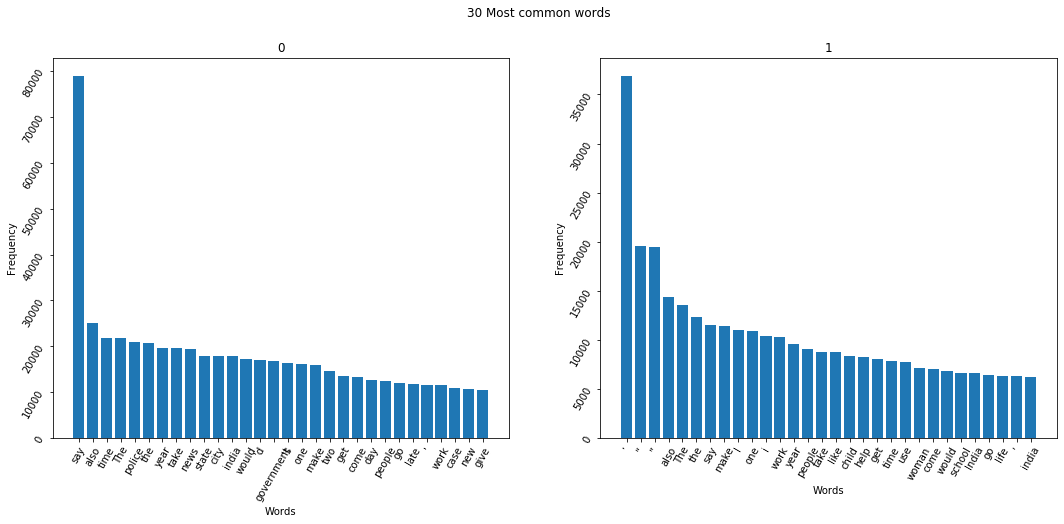

In [101]:
fig, axs = plt.subplots(nrows=1,ncols=2,figsize=(18,7))
fig.figsize = (12,15)
fig.suptitle('30 Most common words')

#faster way to remove stopwords, almost twice as fast as cached process because dictionaries work faster
#stop_words_dict = pd.value_counts(englishStopWords)

for state in pn:
    #word_list = ' '.join(all_data[all_data['is_positive']==state]['clean_content'].values).lower().split()
    #temp_no_stop = [word for word in word_list if word not in stop_words_dict]
    top_30_words_no_stop = pd.value_counts((' '.join(all_data[all_data['is_positive']==state]['lemmatized_content'].values).split()))
    ax = axs[state]
    ax.bar(top_30_words_no_stop.keys()[:30],top_30_words_no_stop[:30])
    ax.set_title(state)
    ax.set_xlabel('Words')
    ax.set_ylabel('Frequency')
    ax.tick_params(rotation=60)
    

    


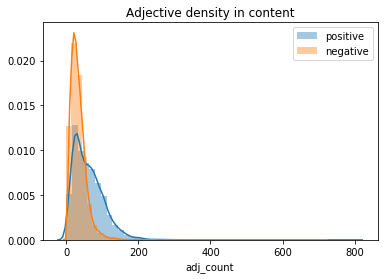

In [102]:
plt.title('Adjective density in content')
sns.distplot(all_data[all_data['is_positive']==1]['adj_count'],label='positive')
sns.distplot(all_data[all_data['is_positive']==0]['adj_count'],label='negative')
plt.legend()

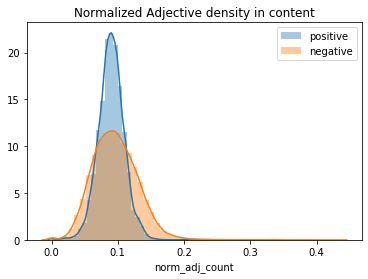

In [103]:
plt.title('Normalized Adjective density in content')
sns.distplot(all_data[all_data['is_positive']==1]['norm_adj_count'],label='positive')
sns.distplot(all_data[all_data['is_positive']==0]['norm_adj_count'],label='negative')
plt.legend()

In [104]:
print('Mean Norm_adjective count in positive articles: ',np.mean(all_data[all_data['is_positive']==1]['norm_adj_count']))
print('std Norm_adjective count in positive articles: ',np.std(all_data[all_data['is_positive']==1]['norm_adj_count']))
print('Mean Norm_adjective count in negative articles: ',np.mean(all_data[all_data['is_positive']==0]['norm_adj_count']))
print('std Norm_adjective count in negative articles: ',np.std(all_data[all_data['is_positive']==0]['norm_adj_count']))
#can consider the feature

Mean Norm_adjective count in positive articles:  0.09004927053874787
std Norm_adjective count in positive articles:  0.019909608872194454
Mean Norm_adjective count in negative articles:  0.09618027747353856
std Norm_adjective count in negative articles:  0.03416253115370078


In [136]:
plt.figure(figsize=(20,8))
plt.title('All adjectives with frequency')
sns.countplot(' '.join(all_data['all_adjs'].values).split())
plt.xlabel('adjective')
plt.ylabel('frequency')

Text(0, 0.5, 'frequency')

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:211: RuntimeWarning: Glyph 35874 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:211: RuntimeWarning: Glyph 2310 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:211: RuntimeWarning: Glyph 2340 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:211: RuntimeWarning: Glyph 2381 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/matplotlib/backends/backend_agg.py:211: RuntimeWarning: Glyph 2350 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/Users/gurumanikanta/anaconda3/lib/python3.7/site

Error in callback <function flush_figures at 0x1a1d2e3048> (for post_execute):


KeyboardInterrupt: 

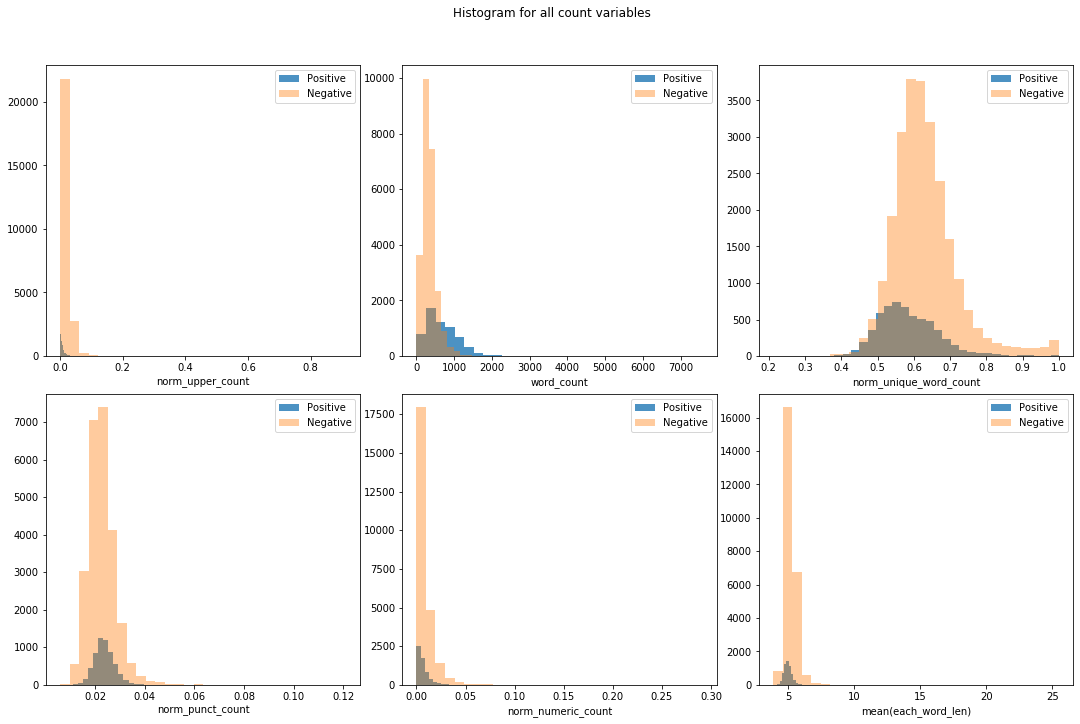

In [111]:
#histogram for the count variables
cols = ['norm_upper_count','word_count','norm_unique_word_count','norm_punct_count','norm_numeric_count','mean(each_word_len)']
fig,ax = plt.subplots(nrows=2,ncols=3,figsize=(15,10))
fig.suptitle('Histogram for all count variables')
fig.tight_layout(h_pad=2)
fig.subplots_adjust(top=0.9)
ax = ax.flatten()


for i,col in zip(range(len(cols)),cols):
    #ax.set_color_cycle(colors)
    ax[i].hist(all_data[all_data['is_positive']==1][col],bins=30,alpha=0.8,label='Positive')
    ax[i].hist(all_data[all_data['is_positive']==0][col],bins=30,alpha=0.4,label='Negative')
    ax[i].set_xlabel(col)
    ax[i].legend()

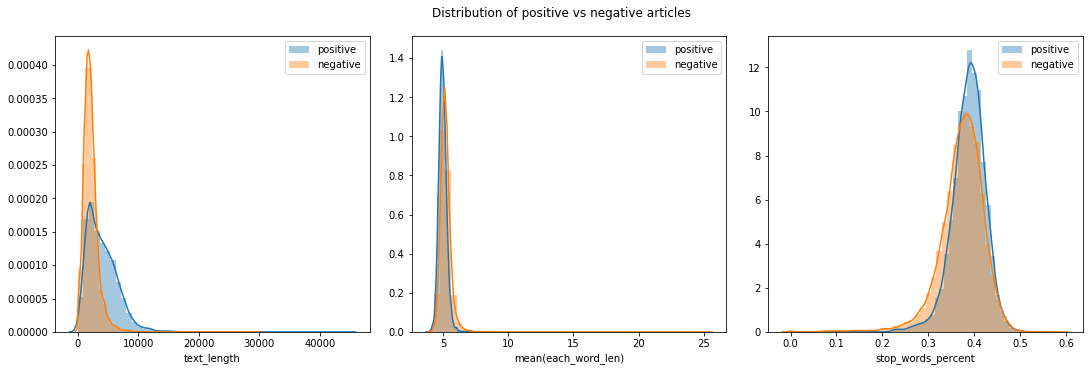

In [112]:
#distplots for few variables
dist_cols = ['text_length','mean(each_word_len)','stop_words_percent']
fig,ax = plt.subplots(nrows=1,ncols=3,figsize=(15,5))
fig.suptitle('Distribution of positive vs negative articles')
fig.tight_layout(h_pad=2)
fig.subplots_adjust(top=0.9)
ax = ax.flatten()
for i,col in zip(range(len(dist_cols)),dist_cols):
    sns.distplot(all_data[all_data['is_positive']==1][col],ax=ax[i],label='positive')
    sns.distplot(all_data[all_data['is_positive']==0][col],ax=ax[i],label='negative')
    ax[i].set_xlabel(col)
    ax[i].legend()
    
#average text length of positive articles seems higher but word count is higher for negative articles 

In [113]:
#there are around 170 articles having more than 10k characters and afer a random check it seems they aren't bogus
all_data[all_data['text_length']>10000].index

Int64Index([15426,  5871,  3650,  5915,  6000,  1985,  5461,  8806,  4029,
            31065,
            ...
              683, 21808,  6609,  2882,   901, 17604,  5770,  2920,  1832,
             1330],
           dtype='int64', length=171)

             upper_count  word_count
upper_count     1.000000    0.342937
word_count      0.342937    1.000000


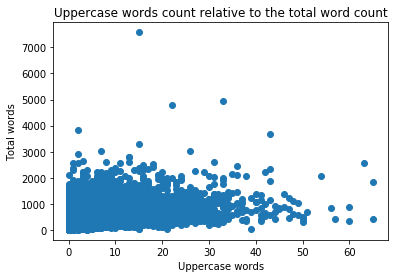

In [114]:
#word count vs upper case word count
plt.scatter(all_data['upper_count'],all_data['word_count'])
plt.title('Uppercase words count relative to the total word count')
plt.xlabel('Uppercase words')
plt.ylabel('Total words')
#not very correlated

print(all_data[['upper_count','word_count']].corr())
#there is a 0.342 correlation

(array([ 0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5, 10.5,
        11.5, 12.5, 13.5, 14.5, 15.5, 16.5, 17.5, 18.5, 19.5]),
 <a list of 20 Text xticklabel objects>)

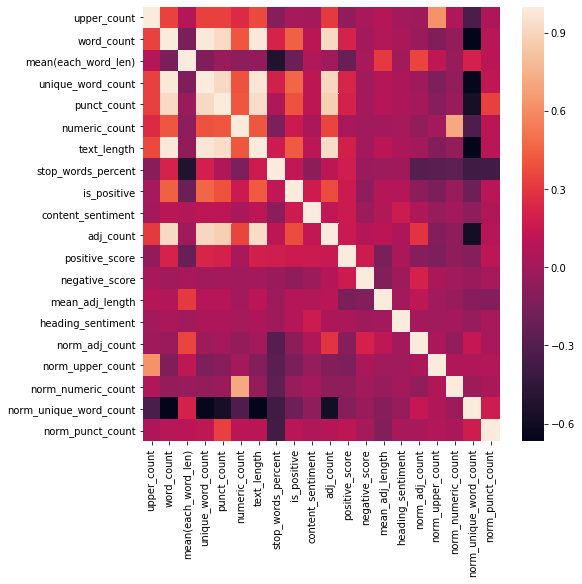

In [116]:
#word_count is very positively corelated to  many features
#interestingly mean_word_len and numeric_count are negatively corelated to stop_words_percent
#corelation of the target to any variable is very small or even 0. Given the volume and distinguishability of data it makes sense
#positive score - distance from most used adjectives to "good", negative score - distance from most used adjectives to "bad"
#no relation at all with any variables for positive and negative scores
plt.figure(figsize=(8,8))
sns.heatmap(all_data.corr())
plt.xticks(rotation=90)

## Content pos

In [117]:
count_vec = CountVectorizer()
pos_count_df = count_vec.fit_transform(all_data['pos_content'])
pos_count_df = pd.DataFrame(data = pos_count_df.toarray() , columns = count_vec.get_feature_names())
pos_count_df['is_positive'] = all_data['is_positive']
pos_count_df.head()

,cc,cd,dt,ex,fw,in,jj,jjr,jjs,md,...,vb,vbd,vbg,vbn,vbp,vbz,wdt,wp,wrb,is_positive
0,0,7,3,0,0,4,63,0,1,0,...,13,3,0,1,18,2,0,0,0,1.0
1,3,9,3,0,0,9,38,1,0,5,...,12,2,8,1,34,2,0,0,1,1.0
2,2,2,4,0,0,9,55,1,0,2,...,5,5,3,2,19,1,2,1,0,1.0
3,0,7,5,0,0,6,21,0,0,3,...,13,2,1,0,8,5,0,0,1,1.0
4,0,5,0,0,3,9,41,0,1,1,...,5,2,1,1,14,3,0,0,0,1.0


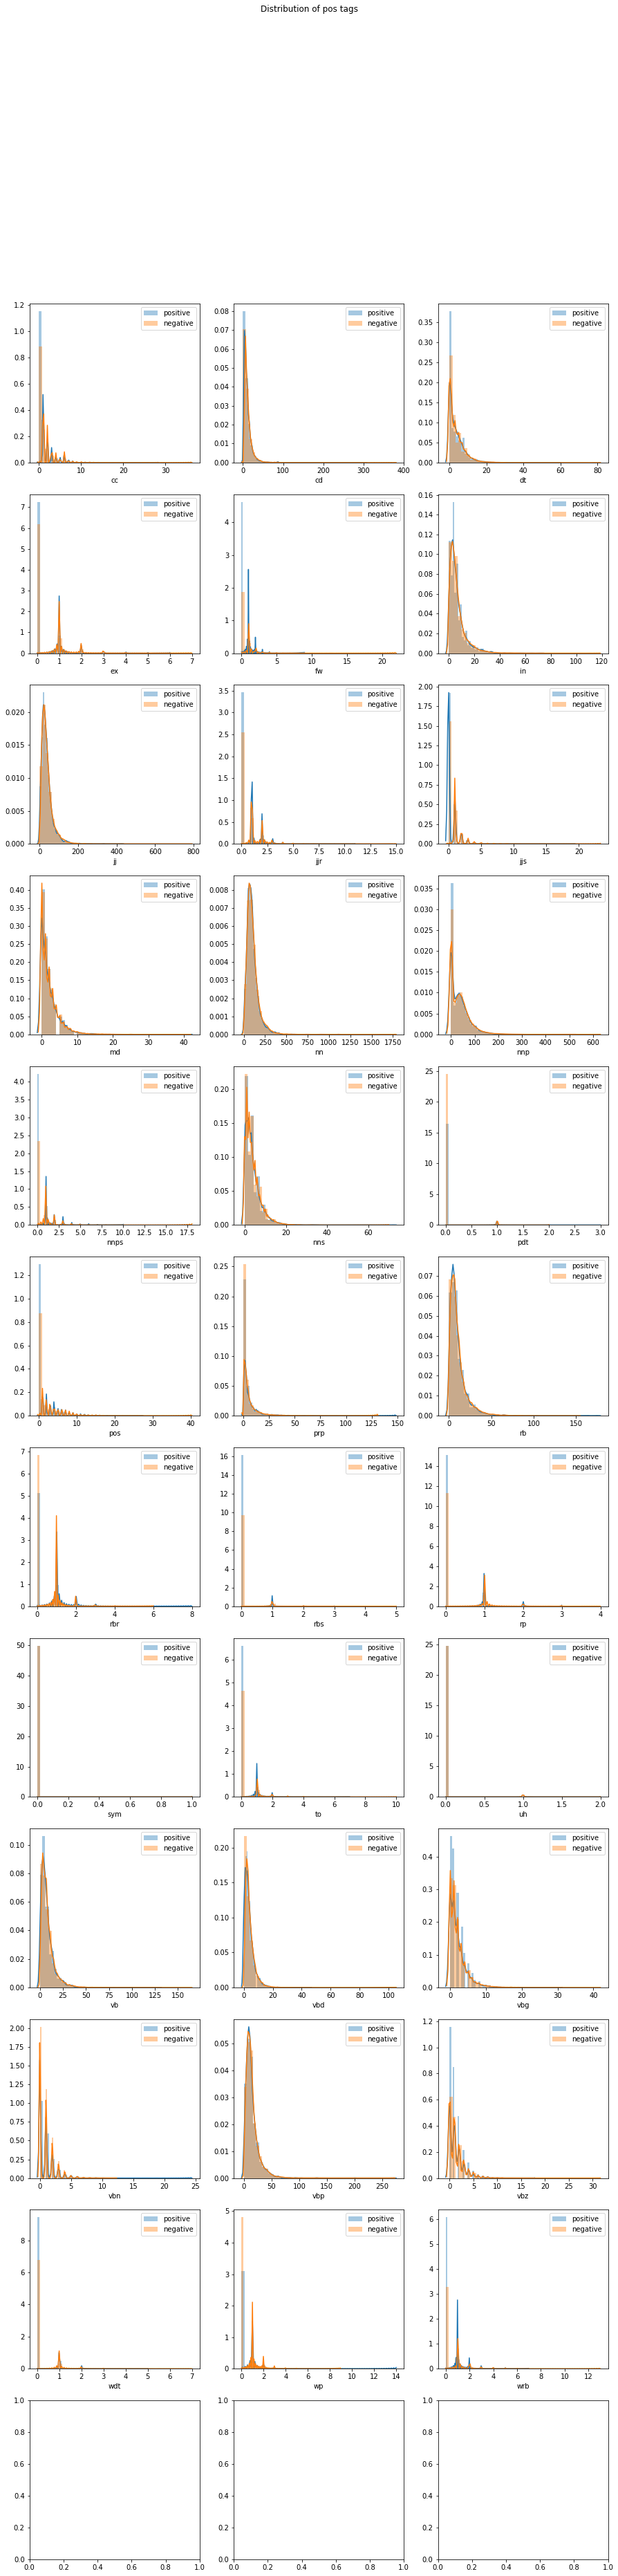

In [118]:
fig, axs = plt.subplots(nrows=12,ncols=3,figsize=(15,60))
axs = axs.flatten()
fig.suptitle('Distribution of pos tags')
col_list = list(pos_count_df.columns[:-1])
for ax,col in zip(axs,col_list):
    sns.distplot(pos_count_df[pos_count_df['is_positive']==1][col],ax=ax,label='positive')
    sns.distplot(pos_count_df[pos_count_df['is_positive']==0][col],ax=ax,label='negative')
    ax.set_xlabel(col)
    ax.legend()

In [119]:
count_vec = CountVectorizer(ngram_range=(2,3),max_features=300)
pos_count_df = count_vec.fit_transform(all_data['pos_content'])
pos_count_df = pd.DataFrame(data = pos_count_df.toarray() , columns = count_vec.get_feature_names())
pos_count_df['is_positive'] = all_data['is_positive']
pos_count_df.head()

,cc nn,cd cd,cd cd nn,cd in,cd in nn,cd jj,cd jj nn,cd nn,cd nn cd,cd nn jj,...,vbp nns,vbp prp,vbp rb,vbp rb jj,vbp vb,vbp vbp,vbz jj,vbz jj nn,vbz nn,is_positive
0,0,0,0,0,0,2,1,4,0,1,...,0,0,0,0,2,1,1,0,0,1.0
1,0,0,0,2,1,1,0,3,0,0,...,1,3,1,0,4,1,0,0,1,1.0
2,1,0,0,0,0,1,0,0,0,0,...,0,0,1,1,1,0,0,0,0,1.0
3,0,0,0,0,0,2,1,3,1,0,...,0,1,0,0,0,1,2,1,1,1.0
4,0,0,0,0,0,0,0,4,0,2,...,0,0,0,0,0,0,2,2,0,1.0


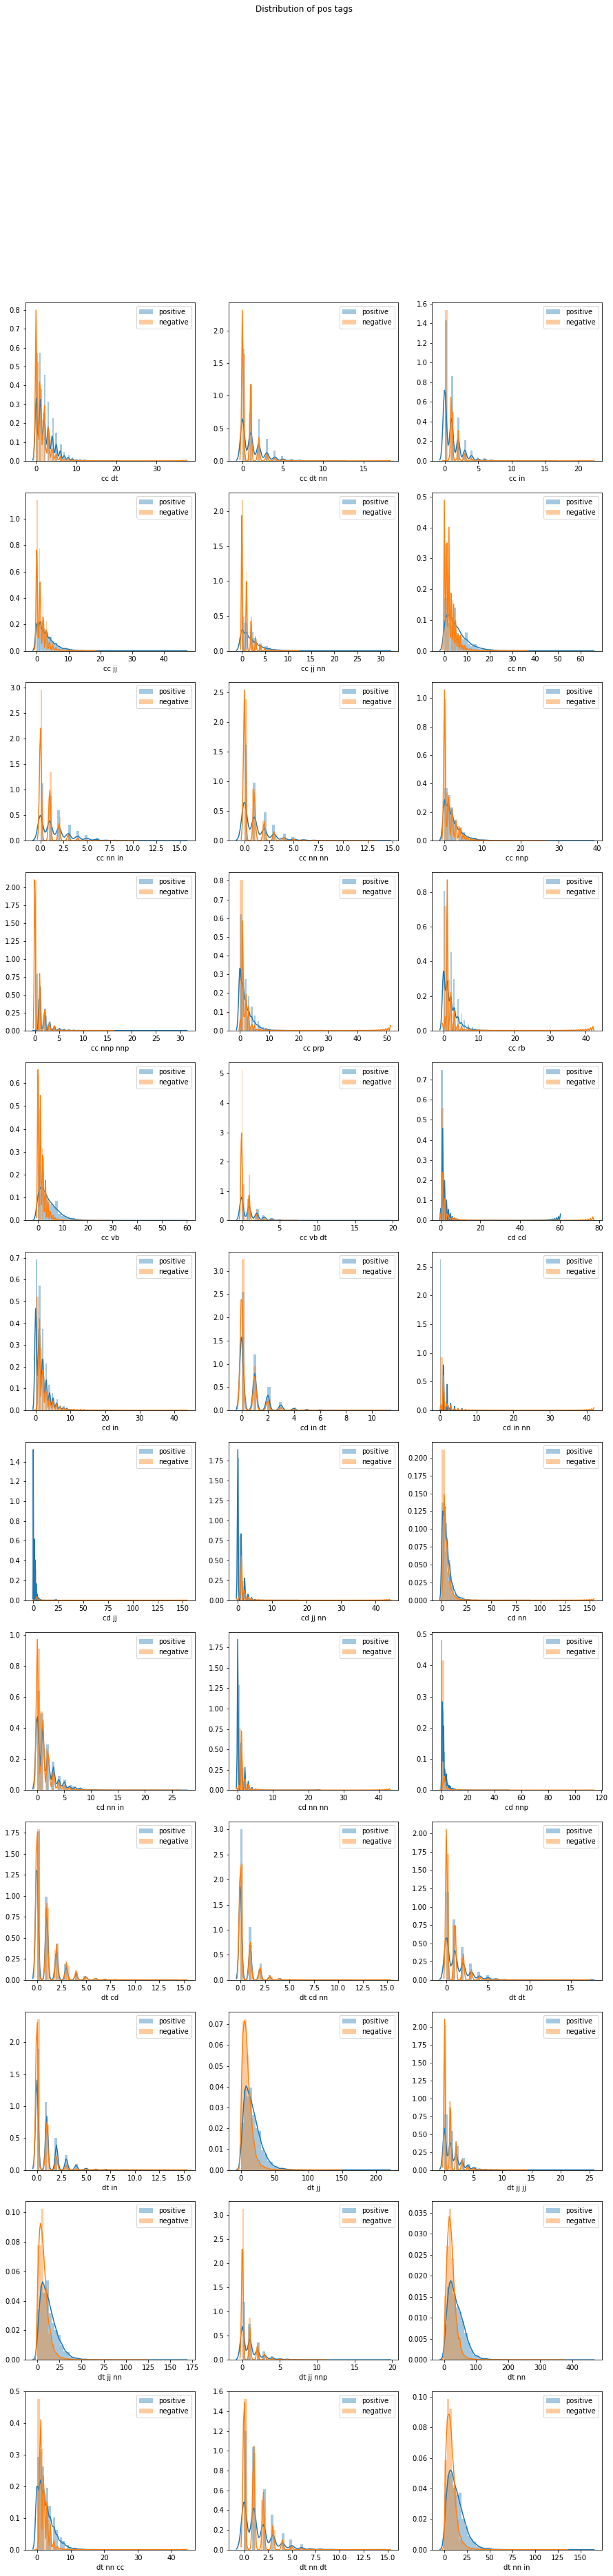

In [486]:
fig, axs = plt.subplots(nrows=12,ncols=3,figsize=(15,60))
axs = axs.flatten()
fig.suptitle('Distribution of pos tags')
col_list = list(pos_count_df.columns[:36])
for ax,col in zip(axs,col_list):
    sns.distplot(pos_count_df[pos_count_df['is_positive']==1][col],ax=ax,label='positive')
    sns.distplot(pos_count_df[pos_count_df['is_positive']==0][col],ax=ax,label='negative')
    ax.set_xlabel(col)
    ax.legend()
    
#cd jj

## Headings pos

In [120]:
count_vec = CountVectorizer(ngram_range=(1,1))
pos_count_df_hd = count_vec.fit_transform(all_data['pos_heading'])
pos_count_df_hd = pd.DataFrame(data = pos_count_df_hd.toarray() , columns = count_vec.get_feature_names())
pos_count_df_hd['is_positive'] = all_data['is_positive']
pos_count_df_hd.head()

,cc,cd,dt,ex,fw,in,jj,jjr,jjs,md,...,vb,vbd,vbg,vbn,vbp,vbz,wdt,wp,wrb,is_positive
0,0,0,0,0,0,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,1.0
1,0,1,0,0,0,0,1,0,0,0,...,0,1,0,0,0,0,0,0,0,1.0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1.0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
4,0,0,0,0,0,0,1,0,1,0,...,0,0,0,0,1,0,0,0,0,1.0


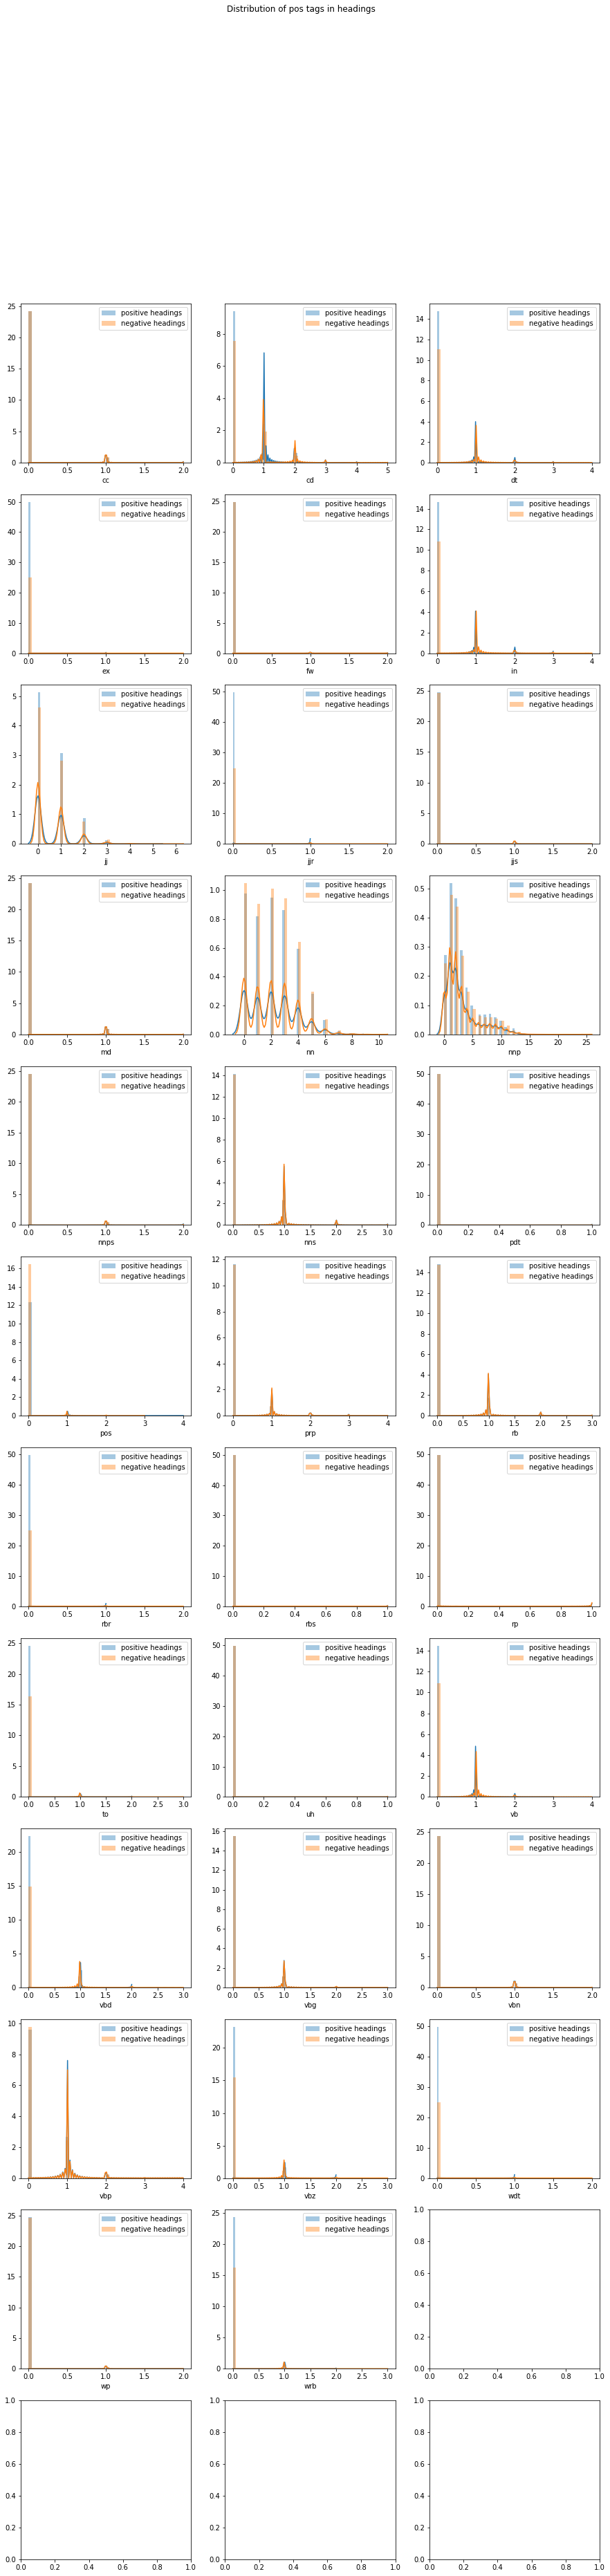

In [121]:
fig, axs = plt.subplots(nrows=12,ncols=3,figsize=(15,60))
axs = axs.flatten()
fig.suptitle('Distribution of pos tags in headings')
col_list = list(pos_count_df_hd.columns[:-1])
for ax,col in zip(axs,col_list):
    sns.distplot(pos_count_df_hd[pos_count_df_hd['is_positive']==1][col],ax=ax,label='positive headings')
    sns.distplot(pos_count_df_hd[pos_count_df_hd['is_positive']==0][col],ax=ax,label='negative headings')
    ax.set_xlabel(col)
    ax.legend()
    


In [122]:
count_vec = CountVectorizer(ngram_range=(2,3),max_features=300)
pos_count_df_hd = count_vec.fit_transform(all_data['pos_heading'])
pos_count_df_hd = pd.DataFrame(data = pos_count_df_hd.toarray() , columns = count_vec.get_feature_names())
pos_count_df_hd['is_positive'] = all_data['is_positive']
pos_count_df_hd.head()

,cc nnp,cc nnp nnp,cd cd,cd cd nn,cd jj,cd jj nn,cd jj nnp,cd nn,cd nn cd,cd nn jj,...,vbz nnp,vbz nnp nnp,vbz vbg,vbz vbg nnp,vbz wrb,wrb jj,wrb nnp,wrb nnp nnp,wrb prp,is_positive
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
1,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,1.0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1.0


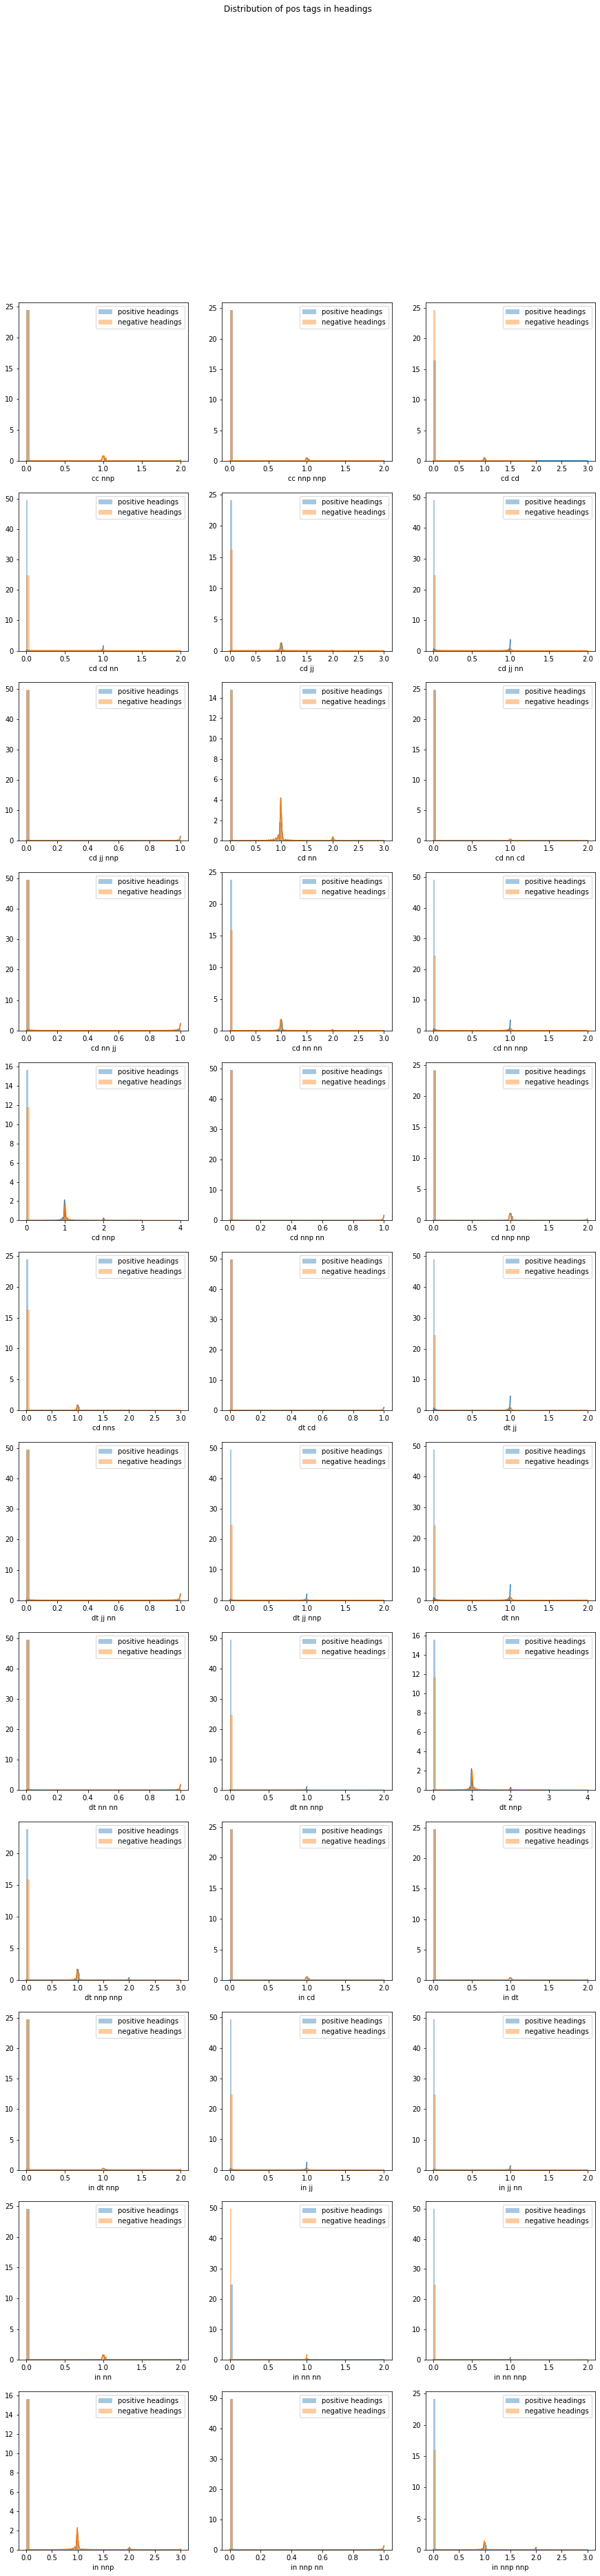

In [123]:
fig, axs = plt.subplots(nrows=12,ncols=3,figsize=(15,60))
axs = axs.flatten()
fig.suptitle('Distribution of pos tags in headings')
col_list = list(pos_count_df_hd.columns[:36])
for ax,col in zip(axs,col_list):
    sns.distplot(pos_count_df_hd[pos_count_df_hd['is_positive']==1][col],ax=ax,label='positive headings')
    sns.distplot(pos_count_df_hd[pos_count_df_hd['is_positive']==0][col],ax=ax,label='negative headings')
    ax.set_xlabel(col)
    ax.legend()

## TFIDF

In [124]:
tfidf = TfidfVectorizer(ngram_range=(1,2),max_features=350)
tfidf_pos = TfidfVectorizer(ngram_range=(1,3),max_features=100)

In [125]:
tfidf_df = tfidf.fit_transform(all_data['lemmatized_content'])
tfidf_df = pd.DataFrame(data = tfidf_df.toarray() , columns = tfidf.get_feature_names())
tfidf_df['is_positive'] = all_data['is_positive']
tfidf_df.head()

,000,10,12,15,20,30,accuse,across,act,action,...,work,world,would,write,year,year old,yet,you,young,is_positive
0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.071612,0.000000,0.0,1.0
1,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.000000,0.089534,0.076406,0.000000,0.000000,0.000000,0.000000,0.0,1.0
2,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.088602,0.0,0.0,...,0.0,0.086781,0.120628,0.102941,0.000000,0.000000,0.098140,0.000000,0.0,1.0
3,0.0,0.0,0.0,0.087241,0.0,0.000000,0.0,0.000000,0.0,0.0,...,0.0,0.000000,0.054201,0.000000,0.047462,0.090531,0.000000,0.091406,0.0,1.0
4,0.0,0.0,0.0,0.000000,0.0,0.078311,0.0,0.000000,0.0,0.0,...,0.0,0.000000,0.000000,0.000000,0.127961,0.000000,0.000000,0.000000,0.0,1.0


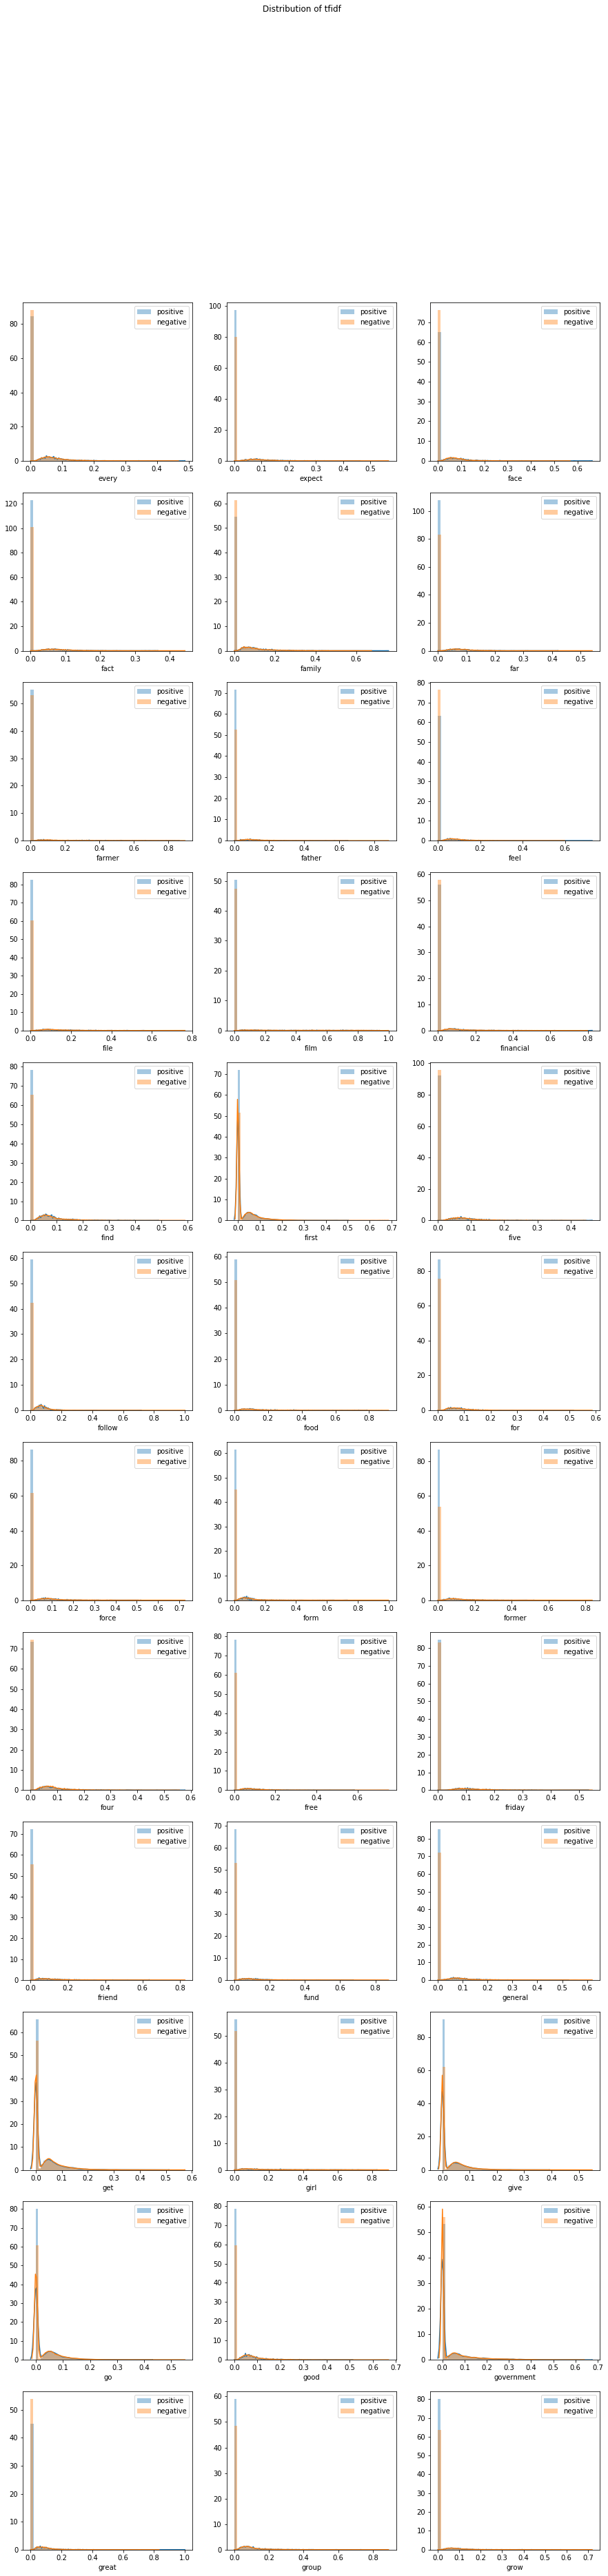

In [126]:
fig, axs = plt.subplots(nrows=12,ncols=3,figsize=(15,60))
axs = axs.flatten()
fig.suptitle('Distribution of tfidf')
col_list = list(tfidf_df.columns[100:136])
for ax,col in zip(axs,col_list):
    sns.distplot(tfidf_df[tfidf_df['is_positive']==1][col],ax=ax,label='positive')
    sns.distplot(tfidf_df[tfidf_df['is_positive']==0][col],ax=ax,label='negative')
    ax.set_xlabel(col)
    ax.legend()

#and, 

## Modeling

In [424]:
#wv is the word2vec embeddings object
#wv['happy']
#each row represents a document averaged by feature for all words
#doc - "this is good", first generate vectors for all 3 words then average each column for all the 3 words.
#Results in single row with with average of all words dimension wise
#that result is finally added to doc_vector i.e, each document will have one row
doc_vector = pd.DataFrame()
def create_mean_w2v(article):
    temp_df = pd.DataFrame()
    for word in set(article.split()):
        try:
            word_embed = wv[word]
            temp_df = temp_df.append(pd.Series(word_embed),ignore_index=True)
        except:
            pass
    return temp_df.mean()

doc_vector = doc_vector.append(all_data['lemmatized_content'].apply(create_mean_w2v))



In [425]:
wv_vec = doc_vector.copy(deep=True)
wv_vec[['text_length','mean_adj_length','unique_word_count','norm_adj_count','is_positive']] = all_data[['text_length','mean_adj_length','unique_word_count','norm_adj_count','is_positive']].copy(deep=True)
wv_vec['cd_jj_usage'] = pos_count_df['cd jj'].to_numpy()
wv_vec[['text_length','mean_adj_length','unique_word_count','adj_counmean_adjective_length','is_positive','cd_jj_usage']] = wv_vec[['text_length','mean_adj_length','unique_word_count','norm_adj_count','is_positive','cd_jj_usage']].progress_apply(minmax_scale)
wv_vec.fillna(value=0,inplace=True)



In [412]:
all_data_test = pd.DataFrame(x_test,columns=['content', 'actual_heading', 'clean_content', 'upper_words',
       'upper_count', 'word_count', 'mean(each_word_len)', 'unique_word_count',
       'punct_count', 'numeric_count', 'text_length', 'stop_words_percent',
       'content_sentiment', 'lemmatized_content', 'pos_content',
       'most_used_adjectives', 'adj_count', 'positive_score', 'negative_score',
       'mean_adj_length', 'heading_sentiment', 'lemmatized_heading',
       'pos_heading'])

all_data_test = norm_numerical_features(all_data_test)
all_data_test['content_sentiment'] = all_data_test['clean_content'].apply(get_document_sentiment)
all_data_test['clean_content'] = all_data_test['clean_content'].apply(rem_contractions)
all_data_test['lemmatized_content'][6620:21635] = all_data_test['clean_content'].apply(lemmatize_with_postag)
all_data_test['pos_content'] = all_data_test['lemmatized_content'].apply(pos_sentence)
all_data_test[['most_used_adjectives','adj_count']] = all_data_test.apply(most_used_adjectives,axis=1,result_type='expand')
all_data_test[['positive_score','negative_score']] = all_data_test.apply(pos_neg_score,axis=1,result_type='expand')
all_data_test[['mean_adj_length','all_adjs']] = all_data_test.apply(mean_adjective_length,axis=1,result_type='expand')
all_data_test['mean_adj_length'].fillna(0,inplace=True)
all_data_test['norm_adj_count'] = all_data_test['adj_count'] / all_data_test['word_count']

all_data_test['heading_sentiment'] = all_data_test['actual_heading'].apply(get_document_sentiment)
all_data_test['lemmatized_heading'] = all_data_test['actual_heading'].apply(lemmatize_with_postag)
all_data_test['pos_heading'] = all_data_test['lemmatized_heading'].apply(pos_sentence)

count_vec_test = CountVectorizer(ngram_range=(2,3),max_features=300)
pos_count_df_test = count_vec_test.fit_transform(all_data_test['pos_content'])
pos_count_df_test = pd.DataFrame(data = pos_count_df_test.toarray() , columns = count_vec_test.get_feature_names())

doc_vector_test = pd.DataFrame()
def create_mean_w2v(article):
    temp_df = pd.DataFrame()
    for word in set(article.split()):
        try:
            word_embed = wv[word]
            temp_df = temp_df.append(pd.Series(word_embed),ignore_index=True)
        except:
            pass
    return temp_df.mean()

doc_vector_test = doc_vector_test.append(all_data_test['lemmatized_content'].apply(create_mean_w2v))
wv_vec_test = doc_vector_test.copy(deep=True)  

wv_vec_test[['text_length','mean_adj_length','unique_word_count','norm_adj_count']] = all_data_test[['text_length','mean_adj_length','unique_word_count','norm_adj_count']].copy(deep=True)

wv_vec_test['cd_jj_usage'] = pos_count_df_test['cd jj'].to_numpy()
wv_vec_test[['text_length','mean_adj_length','unique_word_count','adj_counmean_adjective_length','cd_jj_usage']] = wv_vec_test[['text_length','mean_adj_length','unique_word_count','norm_adj_count','cd_jj_usage']].progress_apply(minmax_scale)
wv_vec_test.fillna(value=0,inplace=True)

In [426]:
x_train = wv_vec.drop(labels=['is_positive'],axis=1).to_numpy()
#x_test = wv_vec_test.to_numpy()

In [427]:
#baseline model Logistic Regression
log_reg = LogisticRegression().fit(x_train,y_train)
pred = log_reg.predict(x_test)
print(accuracy_score(pred,y_test))
print(classification_report(pred,y_test))


/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/sklearn/linear_model/logistic.py:432: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)


0.7903930131004366
              precision    recall  f1-score   support

           0       0.75      0.99      0.85      2083
           1       0.98      0.48      0.64      1352

    accuracy                           0.79      3435
   macro avg       0.86      0.74      0.75      3435
weighted avg       0.84      0.79      0.77      3435



In [587]:
log_reg.coef_

array([[-1.74241354e+00,  3.37015521e+00, -1.92920156e+00,
        -1.47453689e+00,  3.68815694e-01,  2.14226892e+00,
         2.40103915e+00,  2.17156363e+00, -1.01802458e+00,
        -1.29291858e+00,  2.88382601e+00,  1.91948326e-02,
         1.24384973e+00,  1.17418530e+00,  2.46803196e+00,
        -2.49167302e+00, -4.76186120e-01,  2.89163016e-02,
        -1.10855517e+00,  3.41808453e+00,  3.75426017e-01,
         1.95326455e+00,  1.75471286e+00, -1.25706445e+00,
        -1.51719030e+00, -7.49984290e-01,  9.00283253e-03,
         1.40448315e-01, -4.34654573e-01, -2.00600678e+00,
         1.19499180e+00, -2.25803074e+00, -1.40985403e+00,
        -2.03871922e+00,  4.64790846e-01, -1.58335136e-01,
        -3.85221783e+00, -1.79770891e+00, -1.15907612e-01,
         1.34891730e+00, -1.94080751e+00,  2.29883796e+00,
        -4.76928472e+00,  3.80411879e-01,  2.29813396e+00,
        -1.42988500e+00, -3.95926915e+00, -7.05593069e-01,
         2.20141974e+00, -8.27612245e-01, -2.73061329e+0

In [235]:
#lets look at some advanced models to see if they can do a better job given our data


#the default svm model and parameters
svm_mod = svm.SVC(random_state=3)
print(svm_mod.get_params())

###Lets define some Hyperparameters to tune
C = [.0001, .001, .01]
degree = [1, 2, 3, 4, 5]
kernel = ['linear', 'rbf', 'poly']
probability = [True]
gamma = ['scale']


random_grid = {'C': C,
              'kernel': kernel,
              'degree': degree,
              'probability': probability,
              'gamma':gamma
             }


rand = RandomizedSearchCV(estimator=svm_mod, param_distributions=random_grid, n_iter=2, scoring='accuracy', 
                          cv=3, verbose=1, random_state=3)

tqdm(rand.fit(x_train,y_train))

print('best_parameters:svm {}'.format(rand.best_params_))
print('best_accuracy:svm {}'.format(rand.best_score_))    

best_svm = svm.SVC(probability= True, kernel= 'linear', degree= 5, C= 0.0001,random_state=3,gamma='scale')
best_svm.fit(x_train,y_train)
pred = best_svm.predict(x_test)
print(classification_report(y_true=y_test,y_pred=pred))
print(confusion_matrix(y_true=y_test,y_pred=pred))
print(accuracy_score(y_true=y_test,y_pred=pred))
#the model has 97% accuracy but is incapable of predicting positive articles



{'C': 1.0, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': 'auto_deprecated', 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': 3, 'shrinking': True, 'tol': 0.001, 'verbose': False}
Fitting 3 folds for each of 2 candidates, totalling 6 fits


[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   6 out of   6 | elapsed: 56.0min finished


best_parameters:svm {'probability': True, 'kernel': 'poly', 'gamma': 'scale', 'degree': 5, 'C': 0.01}
best_accuracy:svm 0.8238833004495908
              precision    recall  f1-score   support

           0       0.81      1.00      0.89      2773
           1       0.00      0.00      0.00       662

    accuracy                           0.81      3435
   macro avg       0.40      0.50      0.45      3435
weighted avg       0.65      0.81      0.72      3435

[[2773    0]
 [ 662    0]]
0.8072780203784571


/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/sklearn/metrics/classification.py:1437: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)


In [ ]:
#####Decision Tree
#default model
dtc_mod = DecisionTreeClassifier(random_state=3)
print(dtc_mod.get_params())
#default parameters
'''{'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 
'min_impurity_decrease': 0.0, 'min_impurity_split': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 
'min_weight_fraction_leaf': 0.0, 'presort': False, 'random_state': 3, 'splitter': 'best'}'''

#tuning few hyperparameters
random_grid = {'criterion':['gini','entropy'],
               'max_depth':[10,12,15,20,80]}

rand = RandomizedSearchCV(estimator = dtc_mod, param_distributions=random_grid, n_iter=3, scoring='recall', cv=3, 
                          verbose=1, random_state=3)

rand.fit(x_train,y_train)

print('best parameters:dtc {}'.format(rand.best_params_))
print('best recall:dtc {}'.format(rand.best_score_))





In [429]:
best_dtc = DecisionTreeClassifier(criterion='entropy',max_depth=10,random_state=16)
best_dtc.fit(x_train,y_train)
pred = best_dtc.predict(x_test)

print(classification_report(y_true=y_test,y_pred=pred))
print(confusion_matrix(y_true=y_test,y_pred=pred))
print(accuracy_score(y_true=y_test,y_pred=pred))

#though the accuracy is lesser than svm, looks like dtc is able to differentiate pos and neg better than svm


              precision    recall  f1-score   support

           0       0.95      0.72      0.82      2773
           1       0.42      0.84      0.56       662

    accuracy                           0.75      3435
   macro avg       0.68      0.78      0.69      3435
weighted avg       0.85      0.75      0.77      3435

[[2006  767]
 [ 108  554]]
0.745269286754003


In [430]:

#######KNeighborsClassifier
knc_mod = KNeighborsClassifier()
print('default parameters: {}'.format(knc_mod.get_params()))


random_grid = {'weights':['uniform','distance'],
               'n_neighbors':[3,5,7,10,12], 
               'p':[1,2]}

rand = RandomizedSearchCV(estimator=knc_mod, param_distributions=random_grid, n_iter=3, scoring='recall', cv=3,
                          random_state=3)
rand.fit(x_train,y_train)
print('best parameters:knc {}'.format(rand.best_params_))
print('best reacall:knc {}'.format(rand.best_score_))


default parameters: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}
best parameters:knc {'weights': 'distance', 'p': 1, 'n_neighbors': 3}
best reacall:knc 0.8598338407195498


In [431]:
best_knc = KNeighborsClassifier(weights='distance',p=1,n_neighbors=3)
best_knc.fit(x_train,y_train)
pred = best_knc.predict(x_test)

print(classification_report(y_true=y_test,y_pred=pred))
print(confusion_matrix(y_true=y_test,y_pred=pred))
print(accuracy_score(y_true=y_test,y_pred=pred))

              precision    recall  f1-score   support

           0       0.98      0.90      0.94      2773
           1       0.68      0.94      0.79       662

    accuracy                           0.90      3435
   macro avg       0.83      0.92      0.86      3435
weighted avg       0.93      0.90      0.91      3435

[[2482  291]
 [  39  623]]
0.9039301310043668


In [266]:
from sklearn.naive_bayes import GaussianNB

In [435]:
gnb = GaussianNB(var_smoothing=0.00000001)
gnb.partial_fit(x_train,y_train,np.unique(y_train))
pred = gnb.predict(x_test)
print(accuracy_score(y_test,pred))
print(confusion_matrix(y_test,pred))
print(classification_report(y_true=y_test,y_pred=pred))

0.7953420669577875
[[2200  573]
 [ 130  532]]
              precision    recall  f1-score   support

           0       0.94      0.79      0.86      2773
           1       0.48      0.80      0.60       662

    accuracy                           0.80      3435
   macro avg       0.71      0.80      0.73      3435
weighted avg       0.86      0.80      0.81      3435



In [437]:

filename = '/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/gnb.gz'
joblib.dump(gnb,open(filename,'wb'),compress=3)

gnb_loaded = joblib.load(open(filename,'rb'))
pred = gnb_loaded.predict(x_test)
print(classification_report(y_test,pred))

In [239]:

filename = '/Users/gurumanikanta/Documents/DS-Analytics/SupervisedLearning/TPI/TPI/best_knc.sav'
pickle.dump(best_knc,open(filename,'wb'))

trained_knc = pickle.load(open(filename,'rb'))
pred = trained_knc.predict(x_test)
confusion_matrix(y_test,pred)

In [662]:
from sklearn.cluster import KMeans
km = KMeans(n_clusters=5,random_state=3)
tfidf_data = TfidfVectorizer(stop_words="english",ngram_range=(1,2),max_features=500).fit_transform(ie_data['clean_content'])
km.fit(tfidf_data)
pd.value_counts(km.labels_)
#label_list = km.labels_.tolist()
np.where(km.labels_ ==0)[0][:10]

In [748]:
from sklearn.cluster import DBSCAN
dbs = DBSCAN(min_samples=50,eps=0.5)
ie_data.drop_duplicates(subset=['content'],inplace=True)
ie_data.reset_index(inplace=True,drop=True)
tfidf_data = TfidfVectorizer(stop_words="english",ngram_range=(1,2),max_features=500).fit_transform(ie_data['clean_content'])
dbs.fit(tfidf_data)

DBSCAN(algorithm='auto', eps=0.5, leaf_size=30, metric='euclidean',
       metric_params=None, min_samples=50, n_jobs=None, p=None)

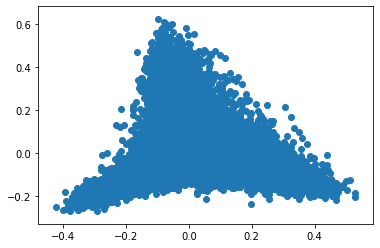

In [754]:
#from sklearn.decomposition import PCA
pca = PCA(n_components=2,random_state=3)
pca_data = pca.fit_transform(tfidf_data.toarray())
plt.scatter(pca_data[:,0],pca_data[:,1])

In [814]:
# Create Document — Topic Matrix
lda_output = ldamodel.transform(data_vec)
# column names
topicnames = ["Topic" + str(i) for i in range(ldamodel.n_components)]
# index names
docnames = ["Doc" + str(i) for i in range(len(text_data))]
# Make the pandas dataframe
df_document_topic = pd.DataFrame(np.round(lda_output, 2), columns=topicnames, index=docnames)
# Get dominant topic for each document
dominant_topic = np.argmax(df_document_topic.values, axis=1)
df_document_topic['dominant_topic'] = dominant_topic
# Styling
def color_green(val):
 color = 'green' if val > .1 else 'black'
 return 'color: {col}'.format(col=color)
def make_bold(val):
 weight = 700 if val > .1 else 400
 return 'font-weight: {weight}'.format(weight=weight)
# Apply Style
df_document_topics = df_document_topic.head(15).style.applymap(color_green).applymap(make_bold)
df_document_topics

,Topic0,Topic1,Topic2,dominant_topic
Doc0,0.89,0.06,0.06,0
Doc1,0.06,0.06,0.89,2
Doc2,0.07,0.07,0.86,2
Doc3,0.03,0.03,0.93,2
Doc4,0.04,0.04,0.92,2


In [971]:
################use this to save and reload models#####################

#import pickle
#filename = 'lda_cluster_10.sav'
#pickle.dump(lda_ie, open(filename, 'wb'))
 
#load the model from disk
loaded_model = pickle.load(open(filename, 'rb'))


In [593]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

'''
reference
from gensim import corpora
dictionary = corpora.Dictionary(text_data)
corpus = [dictionary.doc2bow(text) for text in text_data]

import gensim
NUM_TOPICS = 2
ldamodel = gensim.models.ldamodel.LdaModel(corpus, num_topics = NUM_TOPICS, id2word=dictionary, passes=15)
#ldamodel.save('model5.gensim')
topics = ldamodel.print_topics(num_words=4)
'''


#LDA expectes a document term matrix, convert raw data to doc-term mat
countvec = CountVectorizer(min_df=10,max_features=3000,stop_words="english",ngram_range=(1,1))
ie_data_vec = countvec.fit_transform(all_data['lemmatized_content'])

lda_ie = LatentDirichletAllocation(n_components=10,n_jobs=-1).fit(ie_data_vec) 
lda_ie_out = lda_ie.transform(ie_data_vec) 

#index
ind = ["doc"+str(i) for i in range(len(lda_ie_out))]
#columns
cols = ["topic"+str(i) for i in range(lda_ie.n_components)]
#the dataframe
lda_out_df = pd.DataFrame(lda_ie_out,columns=cols,index=ind)
lda_out_df['dominant_topic'] = np.argmax(lda_out_df.values,axis=1)

dom_topic = lda_out_df['dominant_topic']
#ie_data['dominant_topic'] = lda_out_df['dominant_topic']

topic_words = dict()
vocab = countvec.get_feature_names()
for topic, comp in enumerate(lda_ie.components_):  
    word_idx = np.argsort(comp)[::-1][:20]
    topic_words[topic] = [vocab[i] for i in word_idx]
    
for key,val in topic_words.items():
    print('{}: {}'.format(key,val))
    
lda_out_df.reset_index(inplace=True,drop=False)
#ie_data['dominant_topic'] = lda_out_df['dominant_topic']
fin_dom_topic = lda_out_df['dominant_topic']

0: ['student', 'government', 'state', 'say', 'year', 'college', 'university', 'india', 'education', 'development', 'work', 'project', 'centre', 'school', 'programme', 'scheme', 'minister', 'farmer', 'country', 'provide']
1: ['say', 'india', 'country', 'government', 'indian', 'new', 'president', 'political', 'minister', 'pakistan', 'state', 'party', 'obama', 'issue', 'people', 'make', 'security', 'nuclear', 'leader', 'force']
2: ['say', 'police', 'party', 'congress', 'minister', 'singh', 'state', 'bjp', 'leader', 'election', 'arrest', 'chief', 'district', 'officer', 'station', 'case', 'delhi', 'come', 'day', 'people']
3: ['woman', 'people', 'life', 'year', 'work', 'child', 'family', 'make', 'time', 'help', 'like', 'say', 'come', 'day', 'india', 'know', 'girl', 'old', 'want', 'start']
4: ['court', 'say', 'case', 'government', 'state', 'issue', 'order', 'high', 'official', 'act', 'committee', 'file', 'report', 'justice', 'department', 'law', 'officer', 'authority', 'chief', 'land']
5: ['s

In [594]:
#!{sys.executable} -m pip install pyLDAvis.sklearn
import pyLDAvis.sklearn
import pyLDAvis
pyLDAvis.enable_notebook()
#try parameter mds=tsne
vis = pyLDAvis.sklearn.prepare(lda_ie, ie_data_vec, countvec)
vis

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/pyLDAvis/_prepare.py:257: FutureWarning: Sorting because non-concatenation axis is not aligned. A future version
of pandas will change to not sort by default.

To accept the future behavior, pass 'sort=False'.

To retain the current behavior and silence the warning, pass 'sort=True'.

  return pd.concat([default_term_info] + list(topic_dfs))


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
3     -0.142835 -0.099550       1        1  17.842638
9     -0.085111  0.032015       2        1  14.078242
2      0.134922 -0.134276       3        1  11.823159
8     -0.087091 -0.120097       4        1  11.144732
1      0.064040 -0.087479       5        1   9.631596
0     -0.006911  0.054705       6        1   9.163475
4      0.187864 -0.005493       7        1   7.760114
7     -0.032543  0.088658       8        1   7.383727
6      0.128880  0.171780       9        1   7.023135
5     -0.161213  0.099736      10        1   4.149183, topic_info=     Category          Freq    Term         Total  loglift  logprob
2029  Default  17520.000000  police  17520.000000  30.0000  30.0000
2400  Default  12966.000000  school  12966.000000  29.0000  29.0000
528   Default  13473.000000   child  13473.000000  28.0000  28.0000
2359  Default  14436.000000      rs  14436.000000  27.0000  27.0000
721   Default   9917.000000   court   9917.000000  26.0000  26.0000
...       ...           ...     ...           ...      ...      ...
1300  Topic10   1274.100698    help  14662.281362   0.7392  -5.0194
409   Topic10   1022.024465    book   4979.551988   1.5987  -5.2399
1393  Topic10   1130.170954   india  28323.917828  -0.0391  -5.1393
2389  Topic10   1216.889005     say  82136.567933  -1.0298  -5.0653
1657  Topic10   1070.618177    make  27978.759888  -0.0810  -5.1934

[667 rows x 6 columns], token_table=      Topic      Freq     Term
term                          
1         1  0.147354      000
1         2  0.383814      000
1         3  0.036336      000
1         6  0.191724      000
1         7  0.020085      000
...     ...       ...      ...
2994      5  0.010057    young
2994      6  0.048706    young
2994      8  0.023071    young
2994     10  0.018339    young
2997      5  0.997335  zardari

[3131 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[4, 10, 3, 9, 2, 1, 5, 8, 7, 6])

In [896]:
#topic 2 looks like our target

In [599]:
all_data['dominant_topic'] = fin_dom_topic

In [703]:
pd.value_counts(all_data['dominant_topic'])

2.0    5016
3.0    4072
9.0    3937
8.0    3685
1.0    2857
4.0    2429
0.0    2237
6.0    1776
7.0    1767
5.0     798
Name: dominant_topic, dtype: int64

In [708]:
for topic in [ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9.]:
    print(sum(all_data[all_data['dominant_topic']==topic].index < 6660))
    #topic 3 has most articles from TBI

502
146
93
2907
152
279
111
179
393
1895


In [715]:
all_data[all_data['dominant_topic']==3].index[3500:3520]

Int64Index([19622, 19632, 19633, 19652, 19675, 19676, 19689, 19697, 19710,
            19711, 19728, 19759, 19778, 19795, 19813, 19821, 19834, 19853,
            19869, 19871],
           dtype='int64')

In [752]:
from sklearn.cluster import KMeans
km = KMeans()
km.fit(wv_vec)
#use this to calculate distance from cluster centroid to each data point
transformed = km.transform(wv_vec)
labels = km.predict(wv_vec)
pd.value_counts(labels)
np.where(labels[labels==2])[0][500:520]
#not good performance

In [2]:
from DocumentFeatureSelection.bns import 

     |████████████████████████████████| 808kB 716kB/s eta 0:00:01
  Created wheel for pypandoc: filename=pypandoc-1.4-cp37-none-any.whl size=16731 sha256=1883f17d2a614afda4f949324b4c019a80f17823675b12ee075ebca1a06efd89
  Stored in directory: /Users/gurumanikanta/Library/Caches/pip/wheels/3e/55/4f/59e0fa0914f3db52e87c0642c5fb986871dfbbf253026e639f
  Created wheel for sqlitedict: filename=sqlitedict-1.6.0-cp37-none-any.whl size=14688 sha256=cf3864a1bb5753491437308dacf7626fcda98957dd3a7d5a69ae6d1bff42f5ed
  Stored in directory: /Users/gurumanikanta/Library/Caches/pip/wheels/bd/57/d3/907c3ee02d35e66f674ad0106e61f06eeeb98f6ee66a6cc3fe
Successfully built pypandoc sqlitedict
